### Population view: rasters and PSTHs

The other notebooks look at single trials (the CUSUM runs on each trial's ISIs) or at ISIs pooled over trials. Here all 100 repeats of a condition are shown together: a raster on top (one row per repeat) and the trial-averaged firing rate (PSTH) below it. This shows how the **mean rate** of the population responds to the change at 5 s, and how that depends on autapse strength f.

Two sections, using the raw spike files from `simulate_w_cusum`:
1. **Mean change** (`CPA_cusum_mean_N100_spikes.pickle`): input steps from I_0 to I_0 + h. Same examples as `CPA_divergences_CUSUM_mean.ipynb`.
2. **Variance change** (`CPA_cusum_variance_N100_spikes.pickle`): noise variance jumps from σ² to σ² + Δσ², mean unchanged. Same examples as `CPA_CUSUM_variance.ipynb`.

In each PSTH the dashed lines are the mean rate before (from `T_DISCARD` to the change point) and after the change; the red line marks the true change point, and the grey band is the discarded initial transient.

In [1]:
import inspect
import numpy as np
import matplotlib.pyplot as plt
import pickle
import seaborn as sns
sns.set_theme()

from CPA_with_AQUA import *
from aqua.plotting_functions import plot_raster

In [2]:
tag = 'N100'
SAVE = False
T_DISCARD = 200     # ms, initial transient (as in simulate_w_cusum)
BIN = 50            # ms, PSTH bin width for the full trial
BIN_ZOOM = 10       # ms, PSTH bin width for the zoom around the change point
ZOOM = 500          # ms either side of the change point
EXAMPLE_F = [0, 200, 300, 400]      # columns

sim = {k: p.default for k, p in inspect.signature(simulate_runs).parameters.items()
       if p.default is not inspect.Parameter.empty}

In [3]:
def spike_matrix(saved, v, h, f):
    '''NaN-padded (repeats x spikes) array of spike times [ms] for one condition, for plot_raster'''
    rows = [np.asarray(saved['spikes'][(rep, v, h, f)], dtype = float) for rep in range(saved['N_repeats'])]
    rows = [r[~np.isnan(r)] for r in rows]
    S = np.full((len(rows), max(len(r) for r in rows)), np.nan)
    for i, r in enumerate(rows):
        S[i, :len(r)] = r
    return S


def psth(S, T, bin_ms):
    '''trial-averaged firing rate [Hz]: bin centres [ms] and rate'''
    edges = np.arange(0, T + bin_ms, bin_ms)
    counts, _ = np.histogram(S[~np.isnan(S)], bins = edges)
    return 0.5*(edges[:-1] + edges[1:]), counts / (S.shape[0] * bin_ms/1000)


def mean_rate(S, t0, t1):
    '''mean rate [Hz] over all trials in [t0, t1)'''
    s = S[~np.isnan(S)]
    return np.sum((s >= t0) & (s < t1)) / (S.shape[0] * (t1 - t0)/1000)


def raster_psth_grid(saved, v, h, example_f, title_fn, bin_ms, xlim = None):
    '''
    One column per autapse strength: raster of all repeats (top) and PSTH (bottom).
    title_fn(f, v, h) gives each column's title. xlim = (t0, t1) zooms in.
    '''
    T, cp = saved['T'], saved['changepoint']
    fig, ax = plt.subplots(2, len(example_f), figsize = (4*len(example_f), 6), sharex = 'col', sharey = 'row',
                           gridspec_kw = {'height_ratios': [3, 1]}, squeeze = False)
    for c, f in enumerate(example_f):
        S = spike_matrix(saved, v, h, f)
        fig, ax[0, c] = plot_raster(S, T, ax = ax[0, c], linewidth = 0.4)
        ax[0, c].set_xlabel('')
        ax[0, c].set_ylabel('Trial' if c == 0 else '')
        ax[0, c].grid(False)
        ax[0, c].set_title(title_fn(f, v, h), fontsize = 10)

        t, rate = psth(S, T, bin_ms)
        ax[1, c].step(t, rate, where = 'mid', color = 'k', lw = 1)
        pre, post = mean_rate(S, T_DISCARD, cp), mean_rate(S, cp, T)
        ax[1, c].axhline(pre, xmax = 1, color = plt.cm.viridis(0.15), ls = '--', lw = 1.2)
        ax[1, c].axhline(post, color = plt.cm.viridis(0.85), ls = '--', lw = 1.2)
        ax[1, c].text(0.03, 0.95, f'pre {pre:.1f} Hz\npost {post:.1f} Hz', transform = ax[1, c].transAxes,
                      ha = 'left', va = 'top', fontsize = 8, bbox = dict(facecolor = 'white', alpha = 0.8, edgecolor = 'none'))
        ax[1, c].set_xlabel('Time [ms]')
        ax[1, c].set_ylabel(f'Rate [Hz]\n({bin_ms} ms bins)' if c == 0 else '')

        for a in ax[:, c]:
            a.axvline(cp, color = 'r', ls = '--', lw = 1)
            a.axvspan(0, T_DISCARD, color = 'grey', alpha = 0.3, lw = 0)
            a.set_xlim(*(xlim if xlim is not None else (0, T)))
    fig.tight_layout()
    return fig, ax

## 1. Mean change
The input steps from I_0 to I_0 + h at 5 s. A larger h should give a clear jump in the PSTH. As f grows the neuron bursts (visible as clusters of spikes in the raster), which changes how much the rate moves for the same step.

In [4]:
with open(f'CPA_cusum_mean_{tag}_spikes.pickle', 'rb') as file:
    saved_mean = pickle.load(file)
assert saved_mean.get('change', 'mean') == 'mean'
EXAMPLES_MEAN = [(25.0, 10), (12.5, 20)]     # (variance, step height)
print(f"repeats: {saved_mean['N_repeats']}, T = {saved_mean['T']} ms, change point at {saved_mean['changepoint']} ms")


def title_mean(f, v, h):
    return f'f = {f} pA, e = {sim["e"]}, τ = {sim["tau"]} ms\nstep h = {h} pA, var = {v} pA²'

repeats: 100, T = 10000 ms, change point at 5000 ms


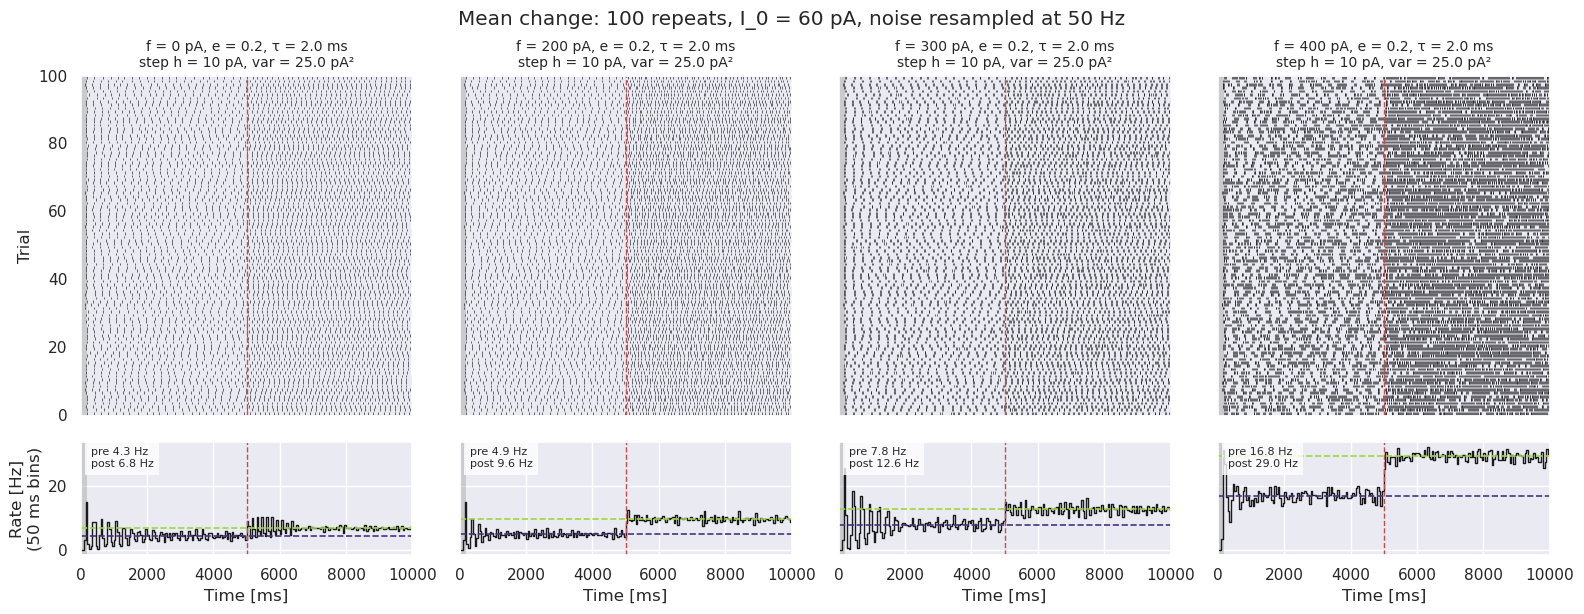

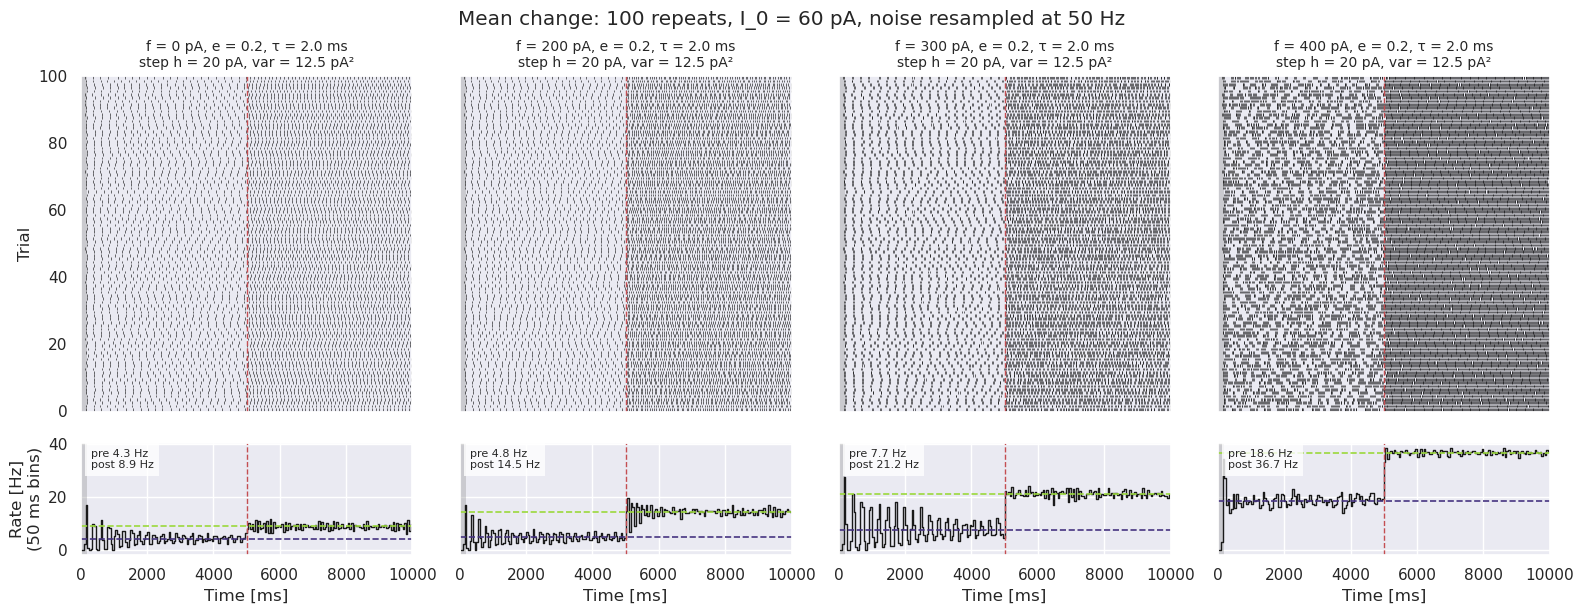

In [5]:
for v, h in EXAMPLES_MEAN:
    fig, ax = raster_psth_grid(saved_mean, v, h, EXAMPLE_F, title_mean, BIN)
    fig.suptitle(f'Mean change: {saved_mean["N_repeats"]} repeats, I_0 = {sim["I_0"]} pA, noise resampled at {sim["noise_rate"]} Hz', y = 1.02)
    if SAVE: plt.savefig(f'./plots/{tag}_mean_raster_psth_v{v}_h{h}.png', bbox_inches = 'tight')
    plt.show()

#### Zoom around the change point
Change point ± `ZOOM` ms with finer bins, to see the transient response to the step.

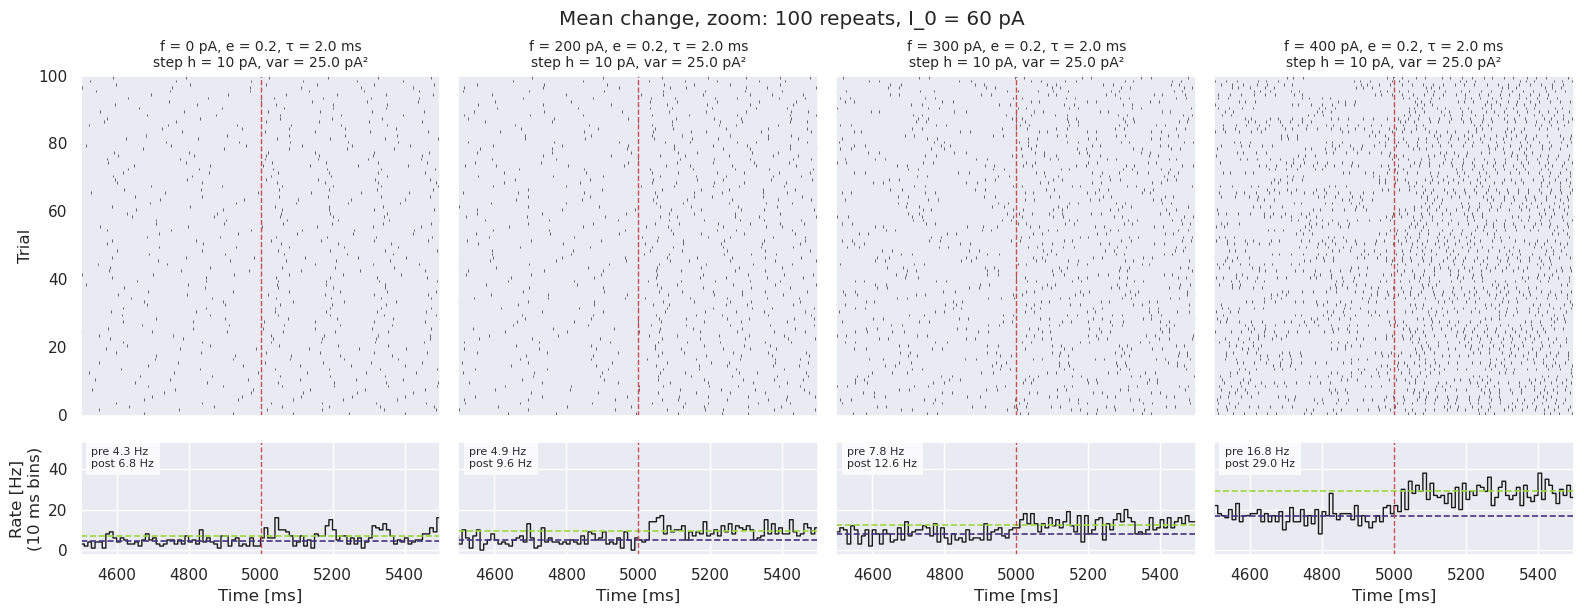

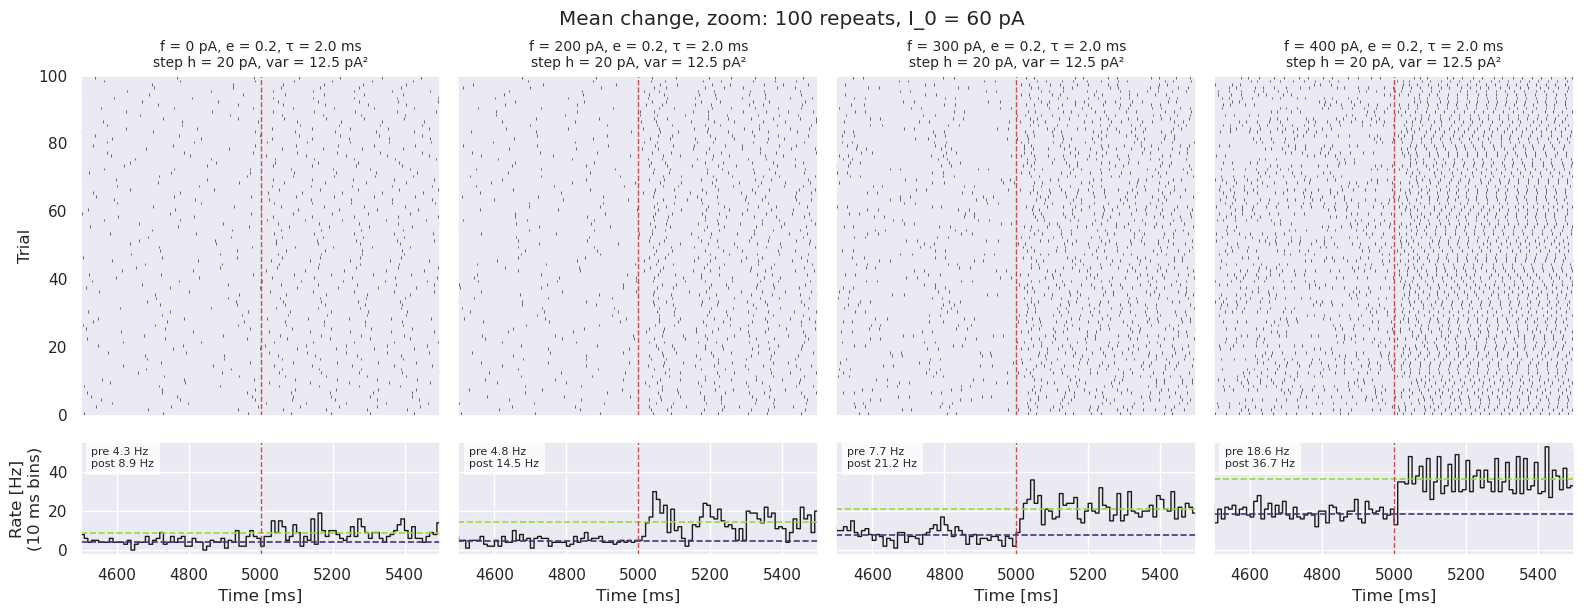

In [6]:
cp = saved_mean['changepoint']
for v, h in EXAMPLES_MEAN:
    fig, ax = raster_psth_grid(saved_mean, v, h, EXAMPLE_F, title_mean, BIN_ZOOM, xlim = (cp - ZOOM, cp + ZOOM))
    fig.suptitle(f'Mean change, zoom: {saved_mean["N_repeats"]} repeats, I_0 = {sim["I_0"]} pA', y = 1.02)
    if SAVE: plt.savefig(f'./plots/{tag}_mean_raster_psth_v{v}_h{h}_zoom.png', bbox_inches = 'tight')
    plt.show()

## 2. Variance change
The mean input stays at I_0 and only the noise variance jumps from σ² to σ² + Δσ². Any change in the mean rate here comes from the neuron's nonlinearity (more large noise excursions above threshold), so the PSTH jump should be much smaller than for a mean step; the change shows up more in how irregular the spiking is.

In [7]:
with open(f'CPA_cusum_variance_{tag}_spikes.pickle', 'rb') as file:
    saved_var = pickle.load(file)
assert saved_var['change'] == 'variance'
EXAMPLES_VAR = [(12.5, 50), (25.0, 100)]     # (baseline variance σ², variance jump Δσ²)
print(f"repeats: {saved_var['N_repeats']}, T = {saved_var['T']} ms, change point at {saved_var['changepoint']} ms")


def title_var(f, v, dv):
    return f'f = {f} pA, e = {sim["e"]}, τ = {sim["tau"]} ms\nσ² = {v} → {v + dv} pA² (Δσ² = {dv})'

repeats: 100, T = 10000 ms, change point at 5000 ms


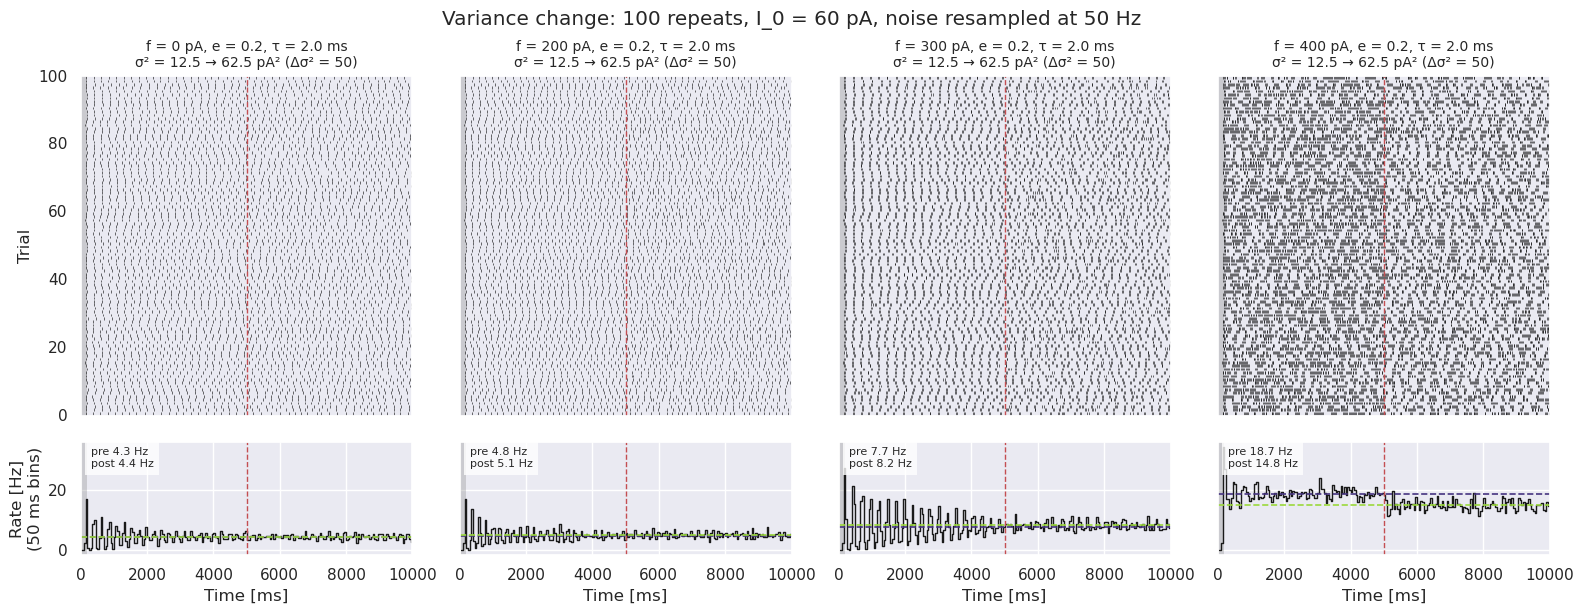

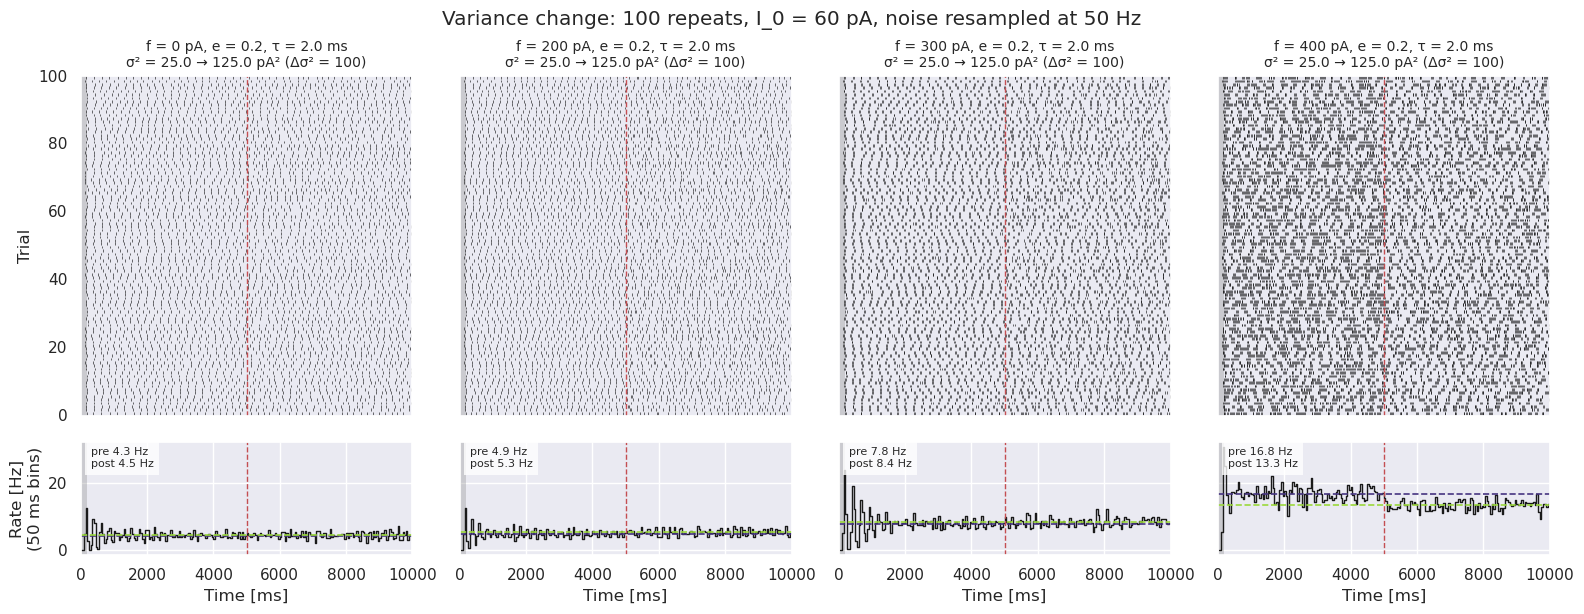

In [8]:
for v, dv in EXAMPLES_VAR:
    fig, ax = raster_psth_grid(saved_var, v, dv, EXAMPLE_F, title_var, BIN)
    fig.suptitle(f'Variance change: {saved_var["N_repeats"]} repeats, I_0 = {sim["I_0"]} pA, noise resampled at {sim["noise_rate"]} Hz', y = 1.02)
    if SAVE: plt.savefig(f'./plots/{tag}_variance_raster_psth_v{v}_h{dv}.png', bbox_inches = 'tight')
    plt.show()

#### Zoom around the change point

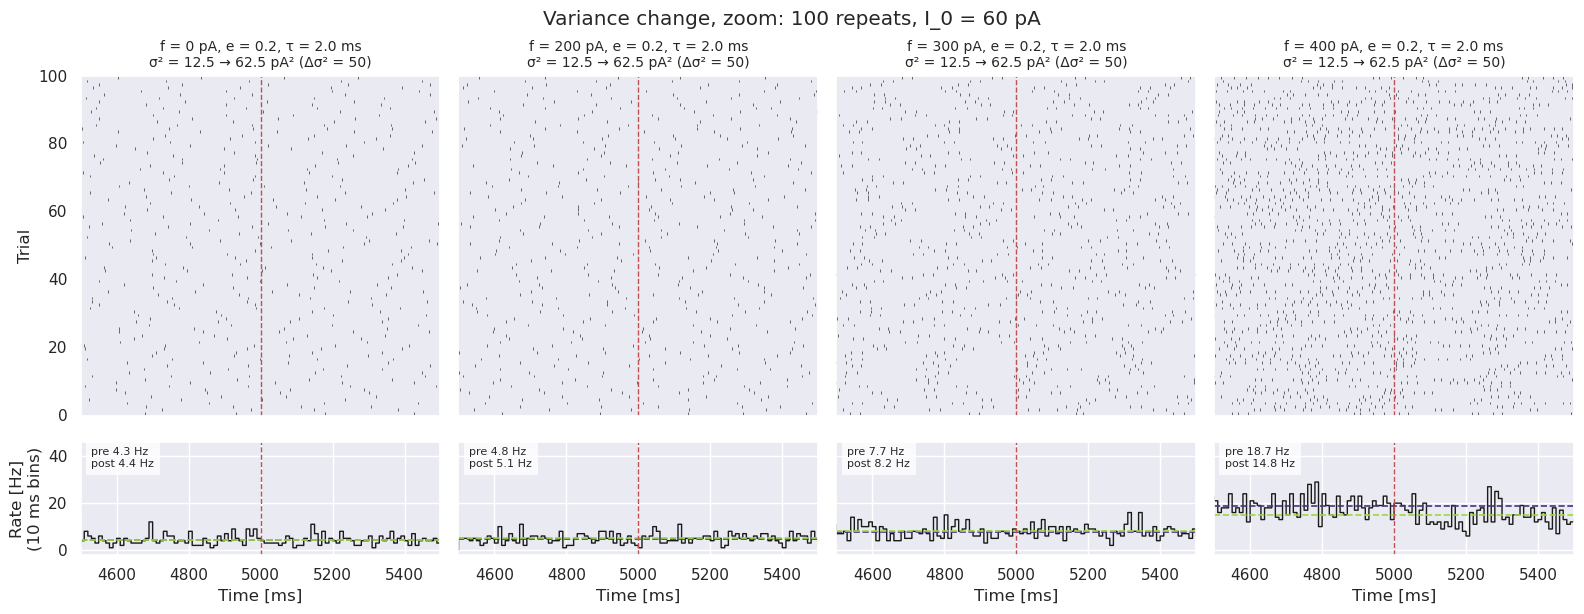

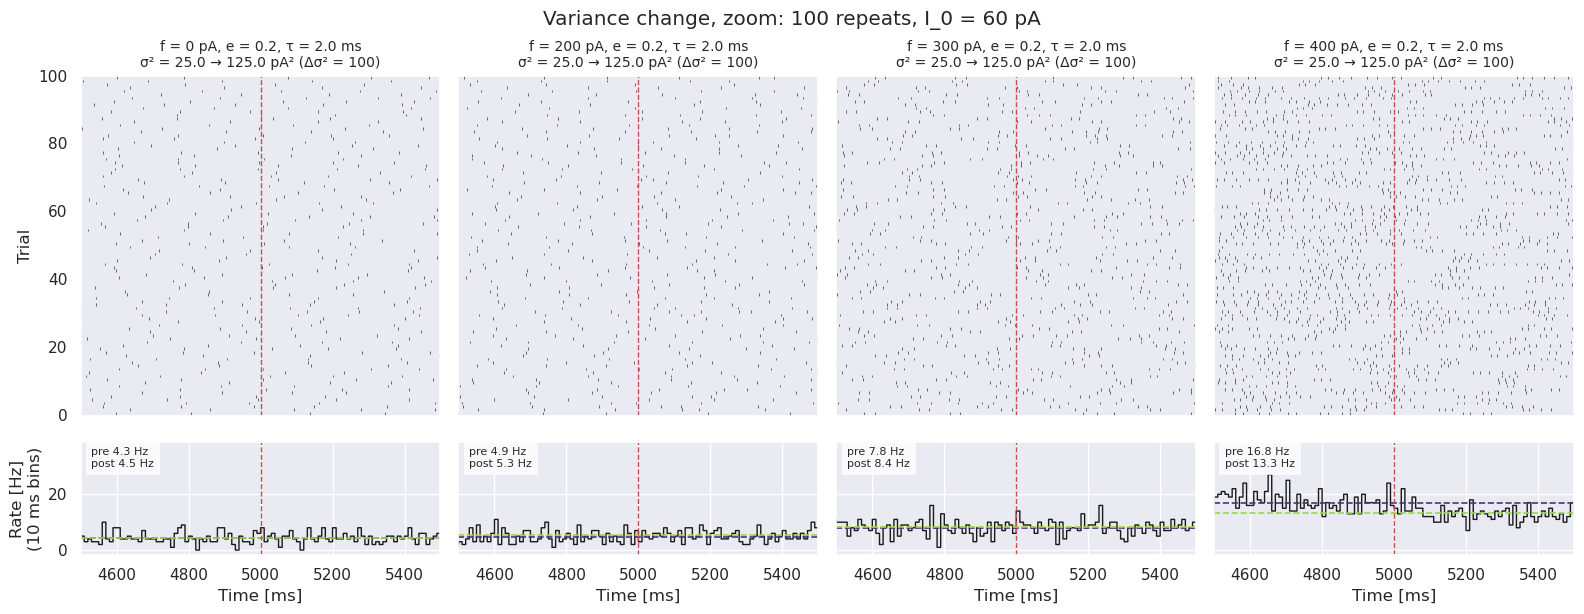

In [9]:
cp = saved_var['changepoint']
for v, dv in EXAMPLES_VAR:
    fig, ax = raster_psth_grid(saved_var, v, dv, EXAMPLE_F, title_var, BIN_ZOOM, xlim = (cp - ZOOM, cp + ZOOM))
    fig.suptitle(f'Variance change, zoom: {saved_var["N_repeats"]} repeats, I_0 = {sim["I_0"]} pA', y = 1.02)
    if SAVE: plt.savefig(f'./plots/{tag}_variance_raster_psth_v{v}_h{dv}_zoom.png', bbox_inches = 'tight')
    plt.show()

## 3. Change point detection on the PSTH

The CUSUM detectors only need a sequence of positive values, their times and fitted pre/post distributions, so they run on PSTHs as well as ISIs. `psth_cusum_analysis` in `CPA_with_AQUA.py` (lead-in functions `psth_resamples`, `reference_bins` in `CP_functions.py`):
- For each condition and population size k = 5, 10, 25, 50: 100 PSTHs, each of k random trials (out of the 100 repeats), 50 ms bins from `T_DISCARD` to T.
- Each bin's value is **count + 1**, so empty bins have a finite density under the existing (positive-only) families.
- The bins of all 100 resamples are pooled into pre/post references (bins ending by / starting at the CP; with 50 ms bins none straddles it). As in the ISI pipeline, the references include the PSTH being scored, and the resamples share trials.
- Methods: `llr` (`fit_isi_distribution` + `llr_cp`) and `ks` (`ks_window_cp`, windows of 5 bins).
- CP resolution is one bin (50 ms).

Results: `CPA_psth_{mean|variance}_N100_{method}.pickle`, one row per resample per k per condition.


At variance 0 every trial is identical, so the bins take only a few distinct values and `fit_isi_distribution` returns no fit (as in the ISI pipeline): `llr` gives no estimate there.

In [10]:
from CPA_with_AQUA import psth_cusum_analysis

PSTH_BIN = 50           # ms, as used for the saved results
K_EXAMPLE = 10          # population size for the worked example
TOL = 100               # ms, hit = |CP - true CP| <= TOL
METHODS = ['llr', 'ks']


def example_llr(saved, v, h, f, k, n_resamples = 100, seed = 0):
    '''one k-trial PSTH (count + 1) of a condition, scored as in psth_cusum_analysis (llr)'''
    trials = [saved['spikes'][(rep, v, h, f)] for rep in range(saved['N_repeats'])]
    X, t_bin = psth_resamples(trials, k, n_resamples, PSTH_BIN, saved['T'], T_DISCARD, np.random.default_rng(seed))
    X = X + 1.
    pre, post = reference_bins(X, t_bin, PSTH_BIN, saved['changepoint'])
    dist_pre, name_pre, _ = fit_isi_distribution(pre)
    dist_post, name_post, _ = fit_isi_distribution(post)
    CP, score, t, l, s = llr_cp(X[0], t_bin, dist_pre, dist_post, return_trace = True)
    return t_bin, X[0], t, l, s, CP, (name_pre, name_post)


def plot_example(saved, v, h, example_f, k, title_fn):
    '''columns: autapse strengths; rows: PSTH (count + 1), per-bin LLR, CUSUM curve'''
    cp = saved['changepoint']
    fig, ax = plt.subplots(3, len(example_f), figsize = (4*len(example_f), 7), sharex = True, squeeze = False)
    for c, f in enumerate(example_f):
        t_bin, x, t, l, s, CP, names = example_llr(saved, v, h, f, k)
        ax[0, c].step(t_bin - PSTH_BIN/2, x, where = 'mid', color = 'k', lw = 1)
        ax[0, c].set_title(title_fn(f, v, h) + f'\nfits: {names[0]} / {names[1]}', fontsize = 10)
        ax[1, c].plot(t, l, color = 'k', lw = 0.8)
        ax[1, c].axhline(0, color = 'grey', lw = 0.8)
        ax[2, c].plot(t, s, color = 'k', lw = 1)
        for a in ax[:, c]:
            a.axvline(cp, color = 'r', ls = '--', lw = 1)
            a.axvline(CP, color = 'b', ls = ':', lw = 1.5)
        ax[2, c].set_xlabel('Time [ms]')
    ax[0, 0].set_ylabel(f'count + 1\n({k} trials, {PSTH_BIN} ms)')
    ax[1, 0].set_ylabel('LLR per bin [nats]')
    ax[2, 0].set_ylabel('CUSUM [nats]')
    fig.tight_layout()
    return fig, ax


def load_psth_results(change):
    '''dict method -> results DataFrame, for the methods whose file exists'''
    out = {}
    for m in METHODS:
        try:
            with open(f'CPA_psth_{change}_{tag}_{m}.pickle', 'rb') as file:
                out[m] = pickle.load(file)
        except FileNotFoundError:
            print(f'missing: CPA_psth_{change}_{tag}_{m}.pickle')
    return out


def hit_rates(res, step_col, true_cp):
    '''fraction of resamples with |CP - true CP| <= TOL, per (f, variance, step, k)'''
    h = hit_rate_curves(res, true_cp, [TOL], group_cols = ('autapse f', 'variance', step_col, 'k'))
    return h.drop(columns = ['tol', 'tol [ms]'])


def plot_hit_vs_step(hits, step_col, xlabel, variance, method):
    '''hit rate vs change size, one panel per k, one line per autapse strength'''
    k_vals = np.sort(hits['k'].unique())
    fig, ax = plt.subplots(1, len(k_vals), figsize = (4*len(k_vals), 4), sharey = True, squeeze = False)
    ax = ax[0]
    for n, k in enumerate(k_vals):
        sub = hits[(hits['k'] == k) & (hits['variance'] == variance)]
        fig, ax[n] = psychometric_curve(sub, x = step_col, y = 'hit rate', fig = fig, ax = ax[n],
                                        add_colorbar = n == len(k_vals) - 1)
        ax[n].set_title(f'k = {k} trials')
        ax[n].set_xlabel(xlabel)
    ax[0].set_ylabel(f'P(|CP error| ≤ {TOL} ms)')
    fig.suptitle(f'{method}: hit rate, variance = {variance}', y = 1.02)
    return fig, ax


def plot_mean_hit_vs_f(hits, step_col, method):
    '''hit rate averaged over change sizes > 0 against autapse strength, one line per k, one panel per variance'''
    sub = hits[hits[step_col] > 0]
    auc = curve_auc(sub, y = 'hit rate', x = step_col, group_cols = ('autapse f', 'variance', 'k'), normalise = True)
    v_vals = np.sort(auc['variance'].unique())
    fig, ax = plt.subplots(1, len(v_vals), figsize = (4*len(v_vals), 4), sharey = True, squeeze = False)
    ax = ax[0]
    for n, v in enumerate(v_vals):
        fig, ax[n] = auc_plot(auc[auc['variance'] == v], hue = 'k', fig = fig, ax = ax[n], errorbar = None,
                              add_colorbar = n == len(v_vals) - 1, colorbar_label = 'k trials')
        ax[n].set_title(f'Variance = {v}')
        ax[n].set_xlabel('Autapse strength f [pA]')
    ax[0].set_ylabel(f'mean P(|CP error| ≤ {TOL} ms)')
    fig.suptitle(f'{method}: hit rate averaged over change sizes > 0', y = 1.02)
    return fig, ax

### 3a. Mean change
Worked example (`llr`, one resample of k = 10 trials): the PSTH, the per-bin log-likelihood ratio and its cumulative sum. The estimated CP (blue, dotted) is the argmin of the CUSUM curve; red dashed is the true CP.

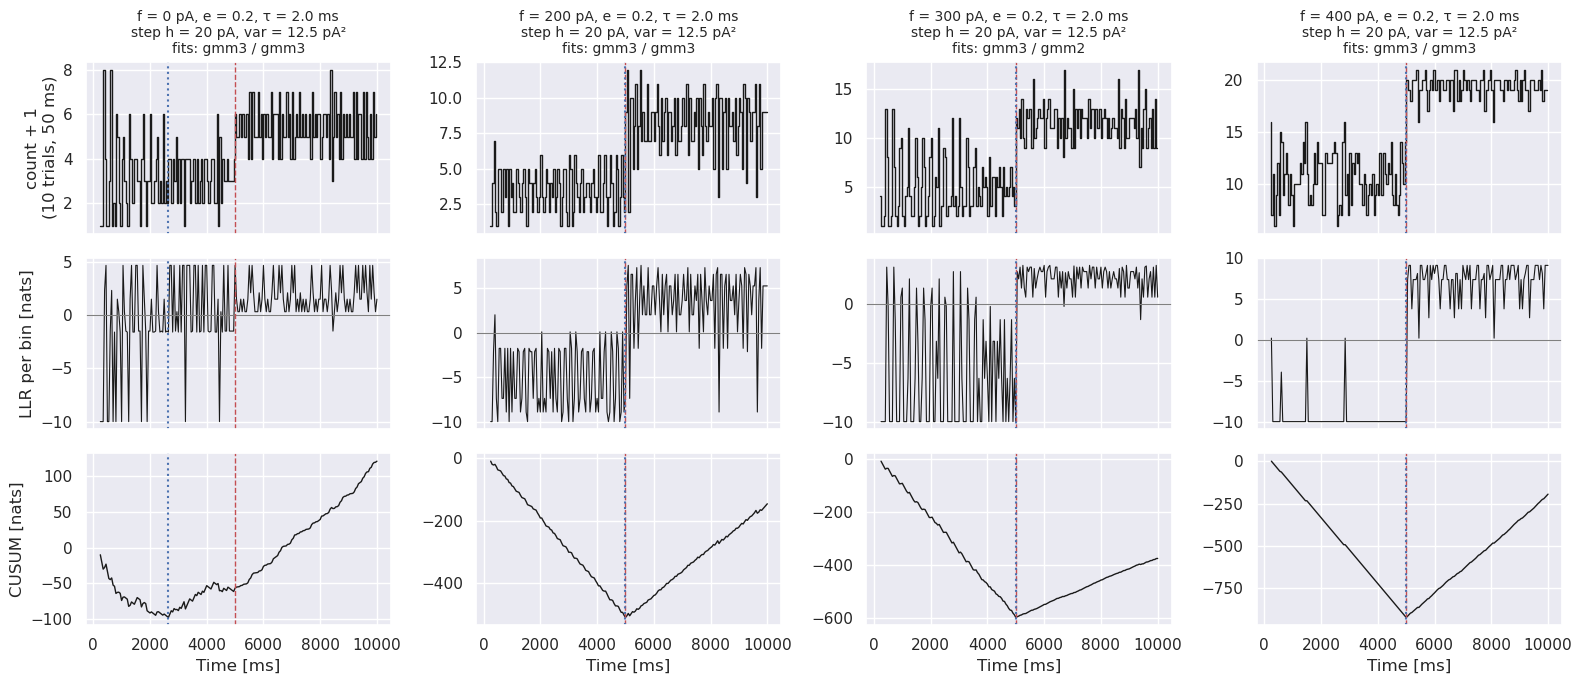

In [11]:
plot_example(saved_mean, 12.5, 20, EXAMPLE_F, K_EXAMPLE, title_mean)
if SAVE: plt.savefig(f'./plots/{tag}_mean_psth_llr_example.png', bbox_inches = 'tight')
plt.show()

Hit rate (estimate within `TOL` of the true CP) against step height, for each population size k. Lines are autapse strengths.

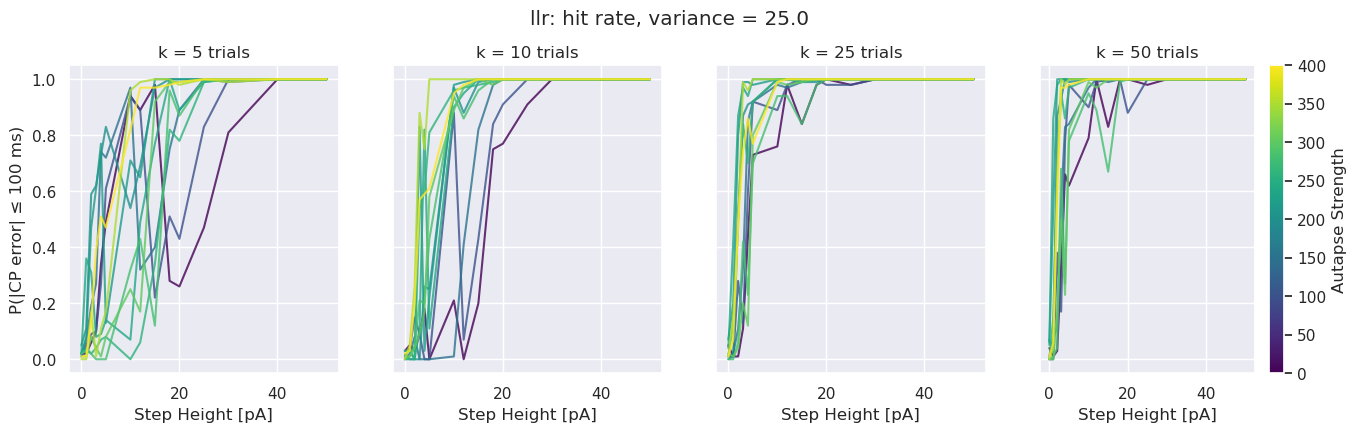

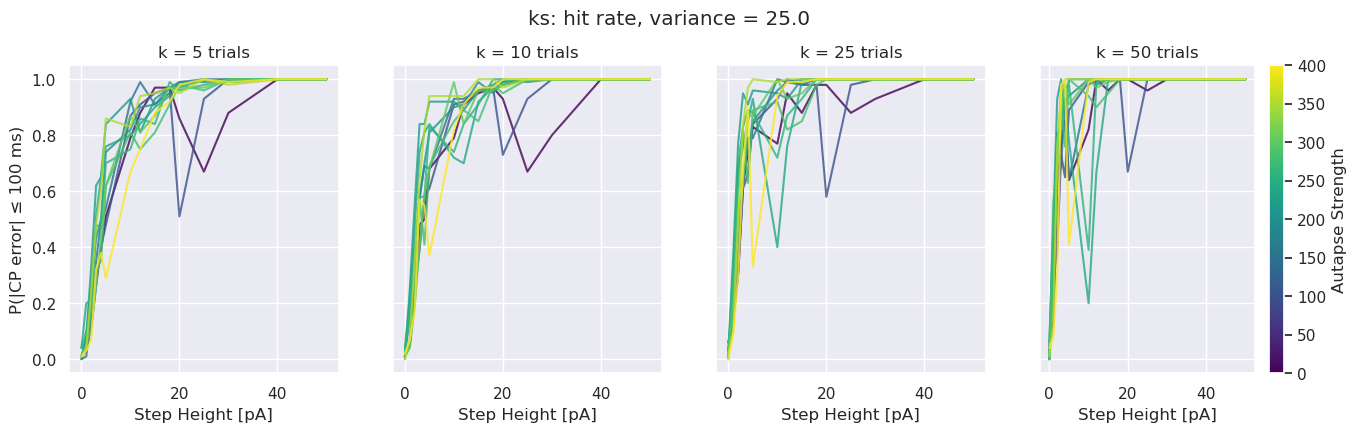

In [12]:
psth_mean = load_psth_results('mean')
hits_mean = {m: hit_rates(res, 'step_height', saved_mean['changepoint']) for m, res in psth_mean.items()}
for m, hits in hits_mean.items():
    plot_hit_vs_step(hits, 'step_height', 'Step Height [pA]', 25.0, m)
    if SAVE: plt.savefig(f'./plots/{tag}_mean_psth_{m}_hit_vs_step.png', bbox_inches = 'tight')
    plt.show()

Hit rate averaged over step heights > 0 (`curve_auc` with `normalise = True`) against autapse strength, one line per k.

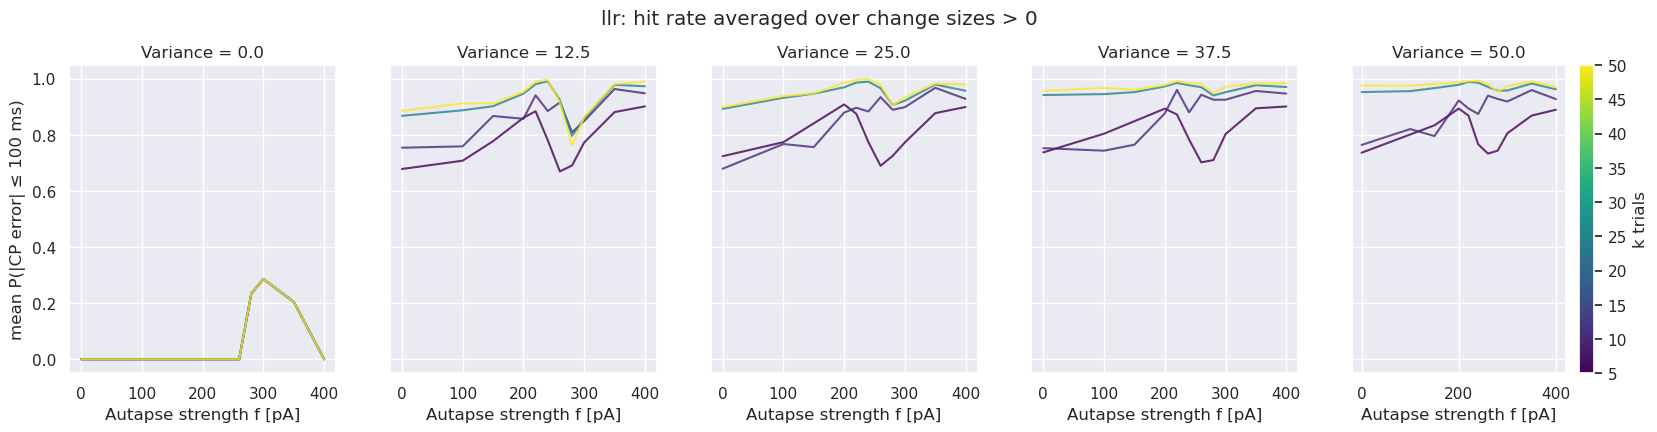

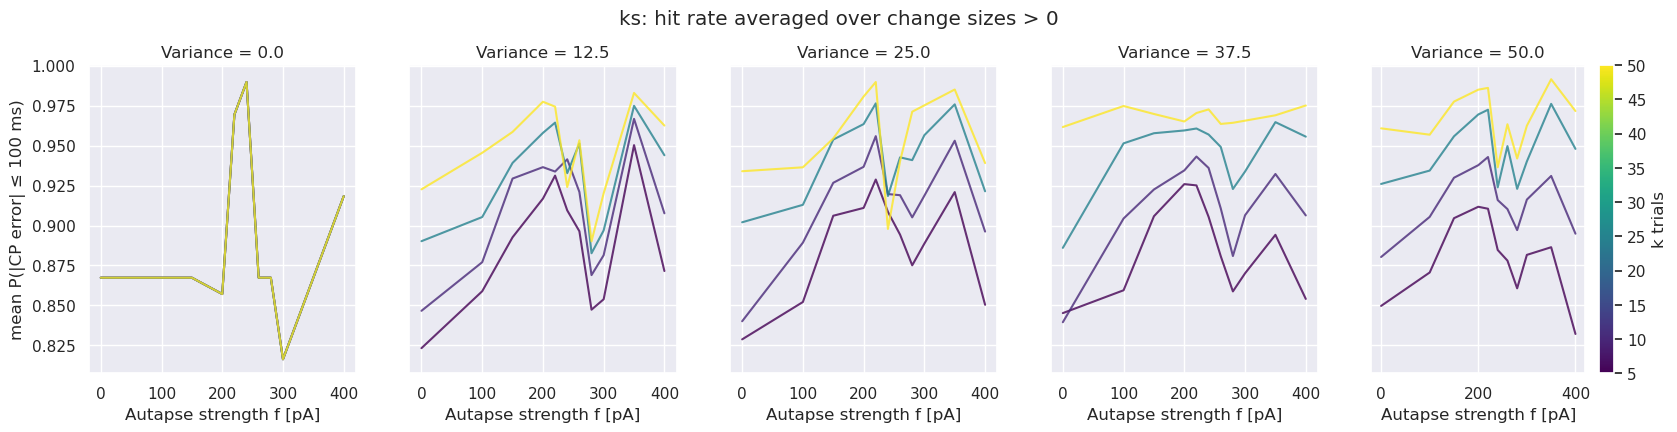

In [13]:
for m, hits in hits_mean.items():
    plot_mean_hit_vs_f(hits, 'step_height', m)
    if SAVE: plt.savefig(f'./plots/{tag}_mean_psth_{m}_hit_vs_f.png', bbox_inches = 'tight')
    plt.show()

### 3b. Variance change
Same plots for the variance change. The mean rate barely moves for f ≤ 300 (section 2), so the `llr` fits have to pick up the change in the spread of the bin counts.

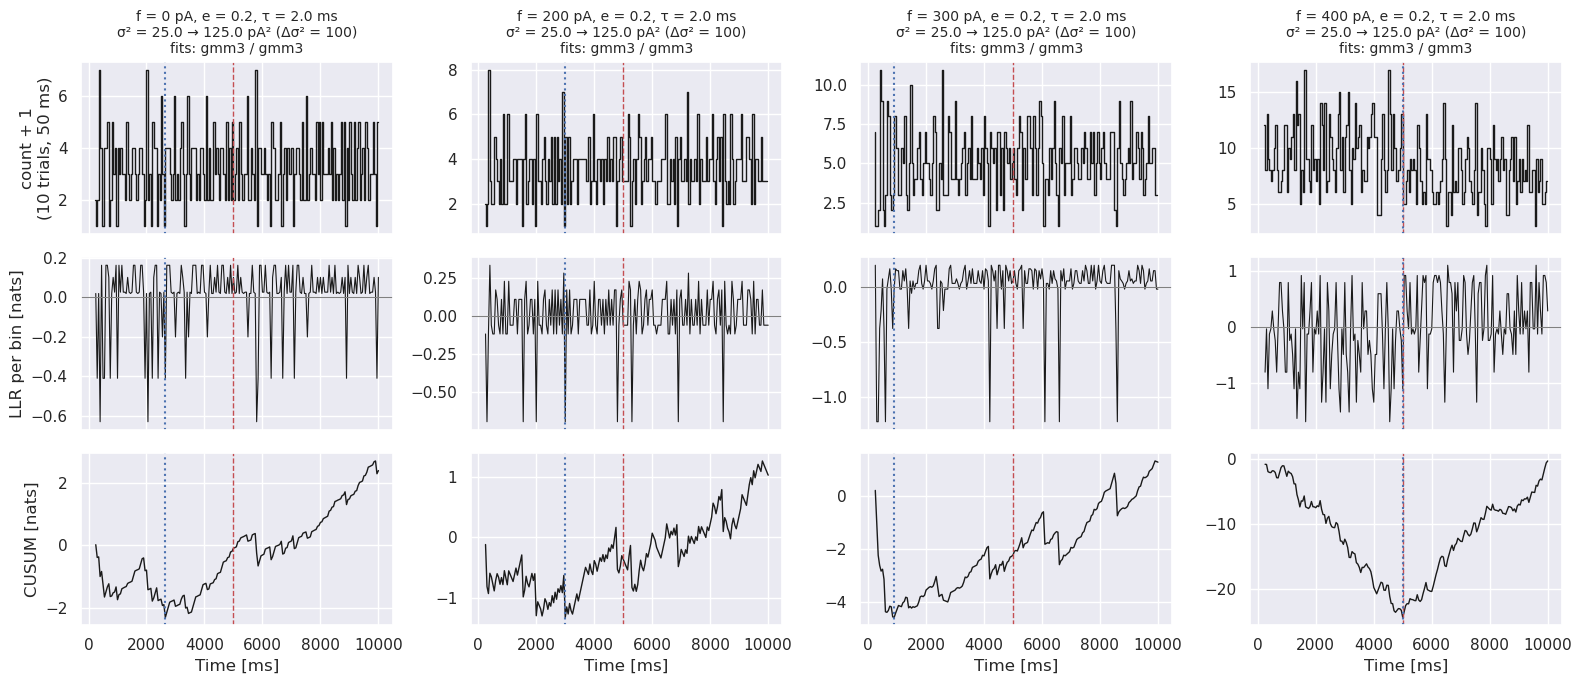

In [14]:
plot_example(saved_var, 25.0, 100, EXAMPLE_F, K_EXAMPLE, title_var)
if SAVE: plt.savefig(f'./plots/{tag}_variance_psth_llr_example.png', bbox_inches = 'tight')
plt.show()

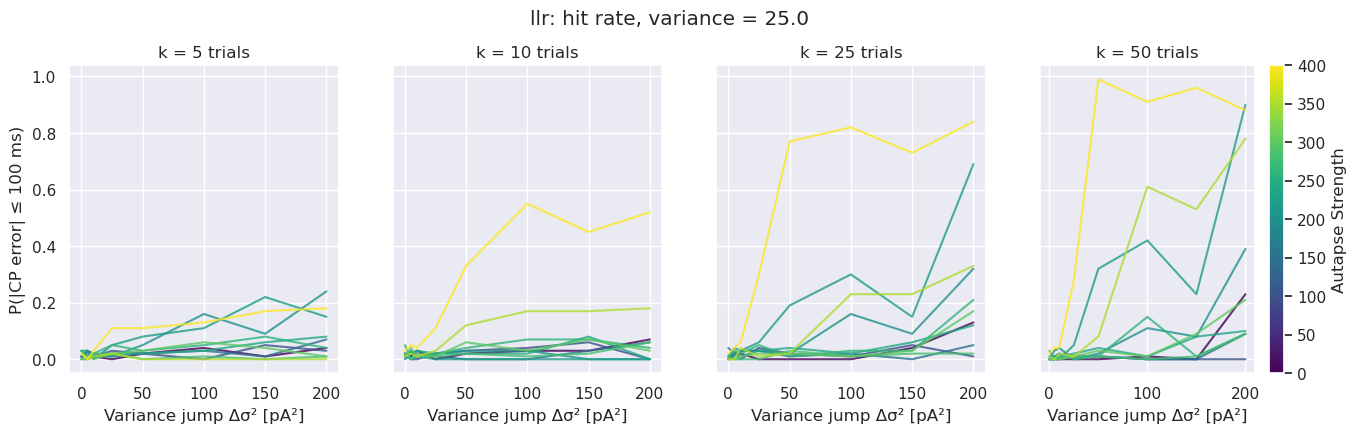

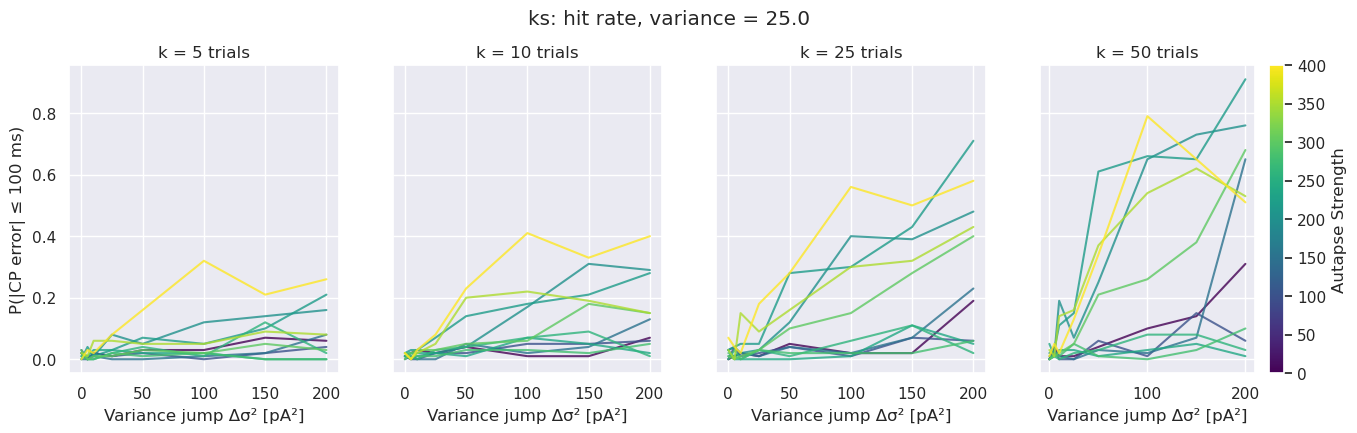

In [15]:
psth_var = load_psth_results('variance')
hits_var = {m: hit_rates(res, 'variance_step', saved_var['changepoint']) for m, res in psth_var.items()}
for m, hits in hits_var.items():
    plot_hit_vs_step(hits, 'variance_step', 'Variance jump Δσ² [pA²]', 25.0, m)
    if SAVE: plt.savefig(f'./plots/{tag}_variance_psth_{m}_hit_vs_step.png', bbox_inches = 'tight')
    plt.show()

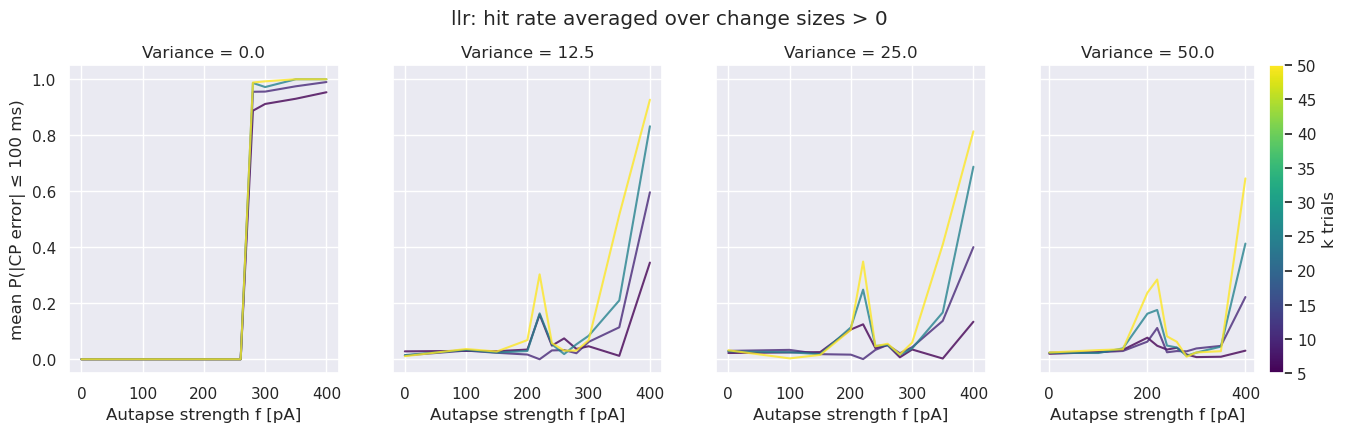

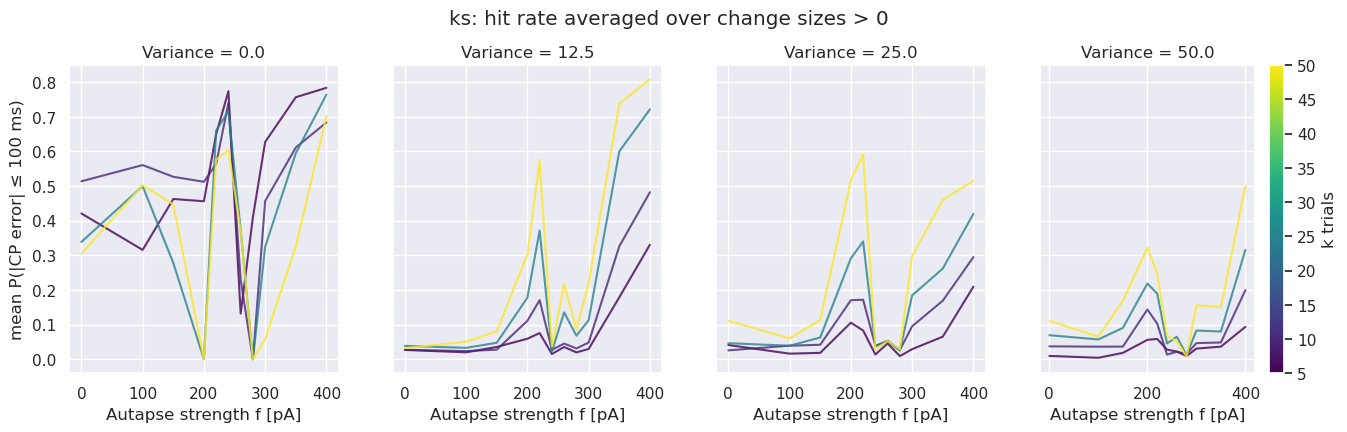

In [16]:
for m, hits in hits_var.items():
    plot_mean_hit_vs_f(hits, 'variance_step', m)
    if SAVE: plt.savefig(f'./plots/{tag}_variance_psth_{m}_hit_vs_f.png', bbox_inches = 'tight')
    plt.show()